# Match filter

## Loading the image (first step)

Libraries and displaying of our test image (using Image and the viridis cmap)

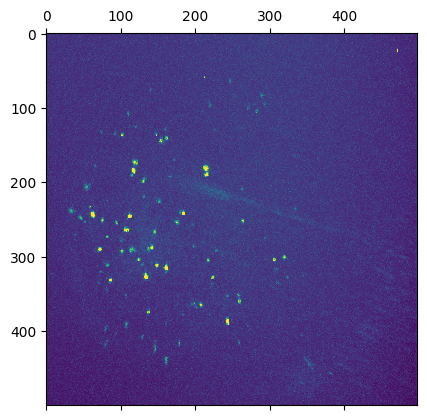

In [23]:
from PIL import Image, ImageFilter
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter
import scipy


pi=np.pi

scan=Image.open('MAX_long_cool_scan.tif')
mattest=np.array(scan)[:, 1:]
plt.matshow(mattest, interpolation='none', cmap='viridis', vmax=np.quantile(mattest, 0.999))
plt.show()

Usual functions to open and show our images (the tif image is converted in a matrix)

In [12]:
def Open_Image(file_name=''):
    file=cv2.imread(file_name, cv2.IMREAD_UNCHANGED)
    mat=np.array(file)
    return mat

def Show_Image(img):
    plt.matshow(img, interpolation='none',cmap='gray', vmax=np.quantile(img, 0.999))
    plt.show()

example of a use of these functions

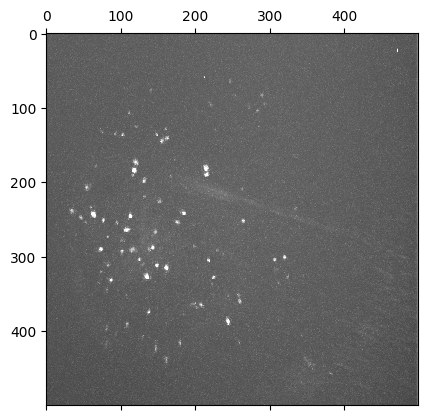

In [13]:
img=Open_Image('MAX_long_cool_scan.tif')
Show_Image(img)

## Gaussian filter

To train with the concept of filter, I used a function from scipy to implement a gaussian filter

In [14]:
def Gaussian_filter(img,sigma,L):
    img_filtered=gaussian_filter(img,sigma=sigma,radius=L)
    return img_filtered

Displaying of the raw images (without and with the filter)

Text(0.5, 1.0, 'filtered (Gaussian)')

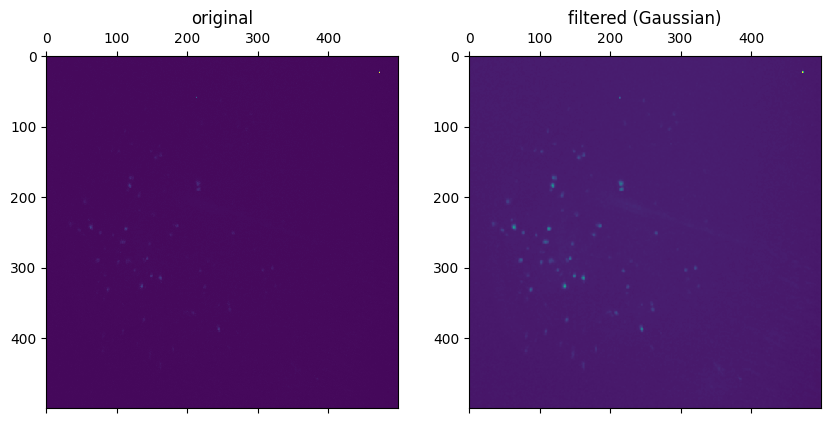

In [15]:
img_filtered=Gaussian_filter(img,1,1)
fig,(ax1,ax2)=plt.subplots(1,2, figsize=(10,10))
ax1.matshow(img)
ax2.matshow(img_filtered)

ax1.set_title('original')
ax2.set_title('filtered (Gaussian)')

Displaying of the images and removing the max that obscuring the interest points (vmax=np.quantile(img_filtered, 0.999))

Text(0.5, 1.0, 'filtered (Gaussian)')

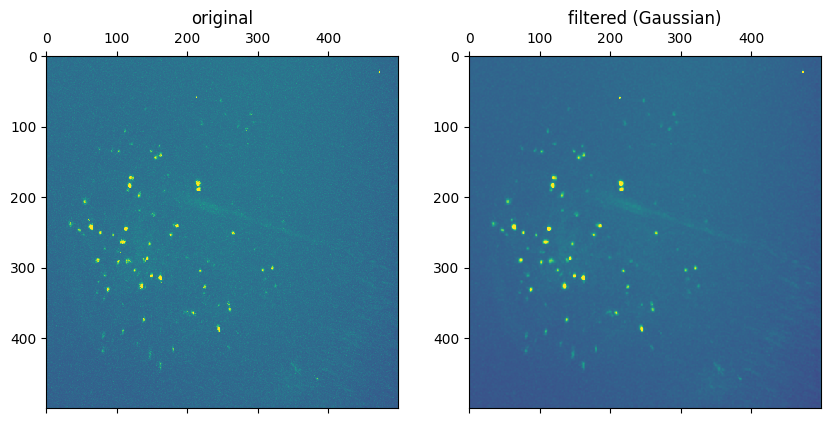

In [16]:
fig,(ax1,ax2)=plt.subplots(1,2, figsize=(10,10))
ax1.matshow(img, interpolation='none', vmax=np.quantile(img, 0.999))
ax2.matshow(img_filtered, interpolation='none', vmax=np.quantile(img_filtered, 0.999))

ax1.set_title('original')
ax2.set_title('filtered (Gaussian)')

## Measuring the PSF 

Little code to evaluate the FWHM of a dot with the max value of a sub image "mat2"

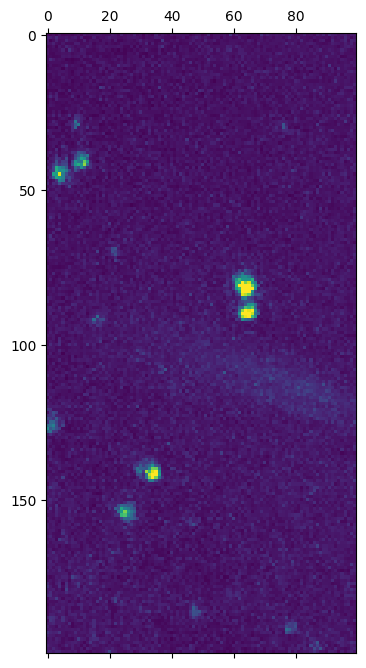

y = 82 x = 64
FWHM ~ 3


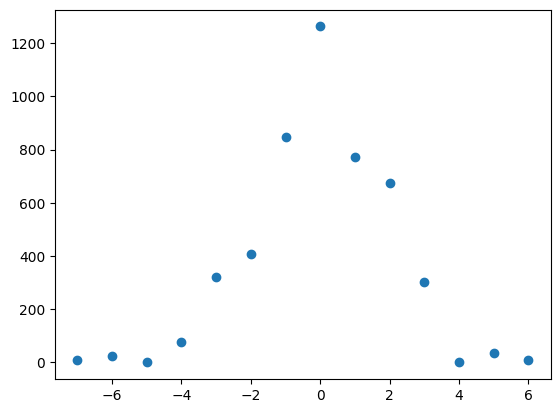

In [ ]:
scan=Image.open('MAX_long_cool_scan.tif')
mattest=np.array(scan)[:, 1:]
mat2=mattest[100:300, 150:250] #creation of a sub image around a interresting dot

plt.matshow(mat2, interpolation='none', cmap='viridis', vmax=np.quantile(mat2, 0.999))
plt.show()

y,x=np.unravel_index(np.argmax(mat2),mat2.shape) #scan of the sub_image to find its max position
print("y =",y,"x =",x)
l=[]
for i in range(-7,7): #scan of the pixel around between -7 and 7, can be modified depending the scale of the dots
    l.append(int(mat2[y][x+i]))
L=np.array(l)
plt.scatter([i for i in range(-7,7)],L-min(l))

fwhm=scipy.signal.peak_widths(L-min(l),[np.argmax(L)], 0.5)
print("FWHM ~",int(fwhm[0][0]))

Calculation of the FWHM

In [18]:
l=[3,2,2,3,4,2,3,3,3,2] #evaluation of the fwhm for different dots
fwhm_mean=np.mean(l)
print("integer value of the fwhm_mean =",(fwhm_mean))


integer value of the fwhm_mean = 2.7


## Poissonian Kernel implementation (from the paper)

Creation of functions to calculate the shape of the PSF, the weight of the PMF kernel and the matrice of the kernel

kernel de taille 3 :
 [[0.08357508 0.15546545 0.08357508]
 [0.15546545 0.28108812 0.15546545]
 [0.08357508 0.15546545 0.08357508]]
kernel de taille 7 :


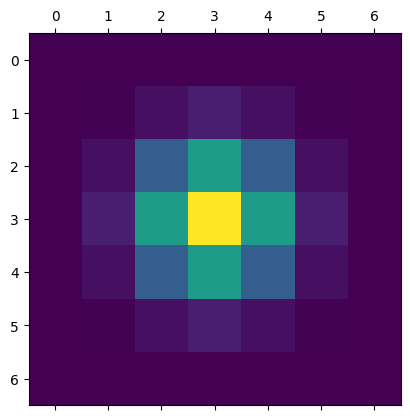

In [ ]:
sigma=(1/2.3548)*fwhm_mean
b=np.quantile(img, 0.10) #background value
a=1789-b #estimation of the signal value, checking the dot max value

def s_mn(m,n,sigma):
    return np.exp(-(1/(2*sigma**2))*(m**2+n**2))/(2*pi*sigma**2) #shape of the PSF (gaussian here)

def w_mn(m,n,a,b,s_mn,sigma):
    return np.log(1+(a/b)*s_mn(m,n,sigma)) #weight of the kernel for a PMF

def Poisson_Kernel(w_mn,L): #creation of the kernel (can be improved)
    K=np.zeros((2*L+1,2*L+1))
    for i in range(0,2*L+1):
        for j in range(0,2*L+1):
            K[i][j]=w_mn(i-L,j-L,a,b,s_mn,sigma)
    return np.array(K)

L=1
print("kernel de taille",2*L+1,":\n",Poisson_Kernel(w_mn,L))
print("kernel de taille 7 :")
plt.matshow(Poisson_Kernel(w_mn,3))


Filtering using cv2 filter and a poissonian kernel of size 3

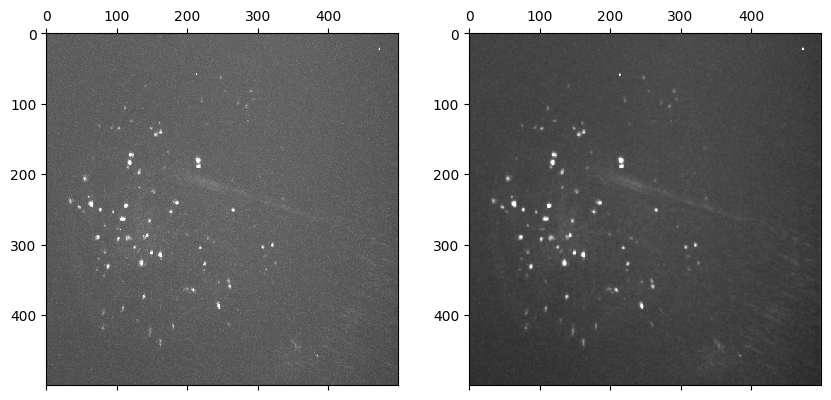

In [20]:
no_filter=np.array([[0,0,0],
                    [0,1,0],
                    [0,0,0]])

raw_img=Open_Image('MAX_long_cool_scan.tif')
filtered_img=cv2.filter2D(raw_img,ddepth=-1,kernel=Poisson_Kernel(w_mn,1))

fig,(ax1,ax2)=plt.subplots(1,2, figsize=(10,10))
ax1.matshow(raw_img, interpolation='none', cmap='gray', vmax=np.quantile(raw_img, 0.999))
ax2.matshow(filtered_img, interpolation='none', cmap='gray', vmax=np.quantile(filtered_img, 0.999))